In [4]:
# gerenciamento de diretórios e arquivos
import os
#gerar gráfico
import matplotlib
#estruturação dos dados
import numpy as np
#gerar gráfico
import seaborn as sns
#gerar gráfico
import matplotlib.pyplot as plt
#Carregar o modelo
from keras.models import load_model
#salvar/carregar arquivos em diferentes formatos
import joblib

In [7]:
diretorio = "./data/imagens de fluorescencia/"
os.listdir(diretorio)[:4]

['Experiment_CHO_745_EFGP_v01_rot165.tif',
 'Experiment_CHO_745_EFGP_v02_rot208.tif',
 'Experiment_CHO_745_EFGP_v03_rot187.tif',
 'Experiment_CHO_745_EFGP_v04_rot227.tif']

In [9]:
#Importando o modelo contendo os valores previstos para o número de células nas imagens
modelo_maior_erro = load_model(f'{diretorio}modelo_fluore_100_75_50_25_2026-10-17.keras')
modelo_maior_erro

In [11]:
X_test_maior_erro = joblib.load(f'{diretorio}imagens_validação_10%_fluore_2026-10-17.gz') #carregando arquivo
X_test_maior_erro.shape

(64, 250, 300, 3)

In [13]:
y_test_maior_erro = joblib.load(f'{diretorio}rótulos_validação_10%_fluore_2026-10-17.gz') #carregando arquivo
y_test_maior_erro.shape

(64,)

In [14]:
#ROTULOS SALVOS EM LISTA

lista_observado_maior_erro = list(y_test_maior_erro)
len(lista_observado_maior_erro)

64

In [15]:
#PREDIÇÃO SALVO EM LISTA

dados_prev = modelo_maior_erro.predict(X_test_maior_erro)
lista_previsto_maior_erro = dados_prev.flatten().tolist()
len(lista_previsto_maior_erro)

2/2 [==============================] - 1s 197ms/step


64

In [16]:
lista_previsto_maior_erro[:10]

[159.9739532470703,
 138.78543090820312,
 52.578582763671875,
 53.6024169921875,
 110.10305786132812,
 76.33389282226562,
 147.36610412597656,
 138.08482360839844,
 130.30259704589844,
 137.55491638183594]

In [17]:
import pandas as pd
from scipy.stats.stats import pearsonr as stats

/tmp/ipykernel_9472/3864774765.py:2: DeprecationWarning: Please use `pearsonr` from the `scipy.stats` namespace, the `scipy.stats.stats` namespace is deprecated.
  from scipy.stats.stats import pearsonr as stats


In [18]:
#DATAFRAME - ORGANIZAÇÃO DAS LISTAS
#COLUNA 1 ROTULO/ COLUNA 2 PREDITO

df_maior_erro = pd.DataFrame(zip(lista_observado_maior_erro,lista_previsto_maior_erro),
                             columns = ['Observed values','Lista preditos'])
df_maior_erro.head()

,Observed values,Lista preditos
0,165,159.973953
1,203,138.785431
2,58,52.578583
3,45,53.602417
4,80,110.103058


In [19]:
#ARREDONDANDO O PREDITO ('lista preditos')

teste = round(df_maior_erro['Lista preditos'],2)
df_maior_erro['Predicted values'] = teste
df_maior_erro.head()

,Observed values,Lista preditos,Predicted values
0,165,159.973953,159.97
1,203,138.785431,138.79
2,58,52.578583,52.58
3,45,53.602417,53.60
4,80,110.103058,110.10


In [20]:
#REORGANIZANDO AS COLUNAS

df_maior_erro = df_maior_erro.reindex(columns=['Observed values','Predicted values','Lista preditos'])
df_maior_erro.head()

,Observed values,Predicted values,Lista preditos
0,165,159.97,159.973953
1,203,138.79,138.785431
2,58,52.58,52.578583
3,45,53.60,53.602417
4,80,110.10,110.103058


In [21]:
#BIBLIOTECA CORRELAÇÃO
from scipy.stats.stats import spearmanr as spearman #importando a biblioteca para gráfico de correlação

/tmp/ipykernel_9472/923420305.py:2: DeprecationWarning: Please use `spearmanr` from the `scipy.stats` namespace, the `scipy.stats.stats` namespace is deprecated.
  from scipy.stats.stats import spearmanr as spearman #importando a biblioteca para gráfico de correlação


In [22]:
from scipy import stats
col1_obt = 0 #Observed value
col2_prev = 1 #Predicted values

# Verifique se as colunas contêm apenas valores numéricos
df_maior_erro[df_maior_erro.columns[col1_obt]] = pd.to_numeric(df_maior_erro[df_maior_erro.columns[col1_obt]], errors='coerce')
df_maior_erro[df_maior_erro.columns[col2_prev]] = pd.to_numeric(df_maior_erro[df_maior_erro.columns[col2_prev]], errors='coerce')

# Remova as linhas com valores NaN resultantes da conversão
df_maior_erro = df_maior_erro.dropna(subset=[df_maior_erro.columns[col1_obt], df_maior_erro.columns[col2_prev]])

# Calcular a correlação
pear_pos_maior_erro = stats.pearsonr(df_maior_erro[df_maior_erro.columns[col1_obt]],
                                     df_maior_erro[df_maior_erro.columns[col2_prev]])

print(pear_pos_maior_erro)

PearsonRResult(statistic=0.8415372568245976, pvalue=3.122509534259447e-18)


<Figure size 1500x1500 with 0 Axes>

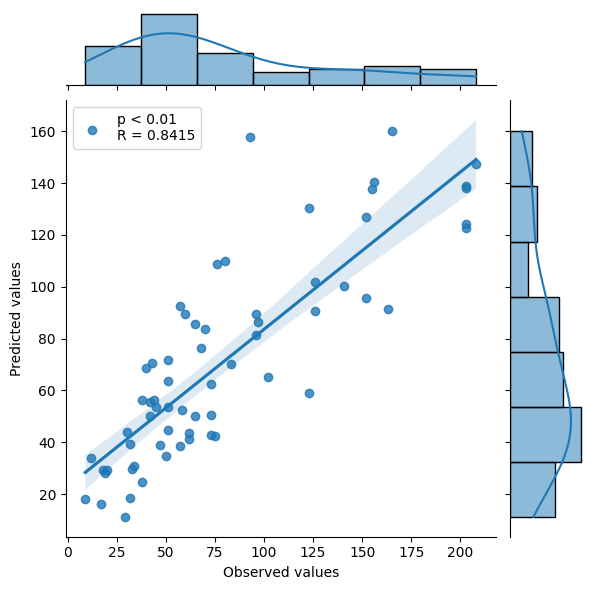

In [23]:
plt.figure(figsize=(15,15))
sns.jointplot(
    x=df_maior_erro.columns[col1_obt],
    y=df_maior_erro.columns[col2_prev],
    kind='reg',
    data=df_maior_erro#[df_maior_erro['Lista observado'] > 300]
)

if pear_pos_maior_erro[1] < 0.01:
  plt.legend(['p < ' + '0.01' + '\nR = ' + str(round(pear_pos_maior_erro[0], 4))]) #calculando p e relse:
else:
  plt.legend(['p = ' + str(round(pear_pos_maior_erro[1],4)) + '\nR = ' + str(round(pear_pos_maior_erro[0], 4))]) #calculando p e r

#Predição do modelo

In [24]:
predictions = modelo_maior_erro.predict(X_test_maior_erro)

2/2 [==============================] - 1s 178ms/step


In [25]:
# Compara as previsões com os valores reais
for i in range(len(predictions)):
    print(f"Valor real: {y_test_maior_erro[i]}, Valor predito: {predictions[i]}")

Valor real: 165, Valor predito: [159.97395]
Valor real: 203, Valor predito: [138.78543]
Valor real: 58, Valor predito: [52.578583]
Valor real: 45, Valor predito: [53.602417]
Valor real: 80, Valor predito: [110.10306]
Valor real: 68, Valor predito: [76.33389]
Valor real: 208, Valor predito: [147.3661]
Valor real: 203, Valor predito: [138.08482]
Valor real: 123, Valor predito: [130.3026]
Valor real: 155, Valor predito: [137.55492]
Valor real: 126, Valor predito: [101.9002]
Valor real: 203, Valor predito: [124.04845]
Valor real: 43, Valor predito: [70.4467]
Valor real: 70, Valor predito: [83.69679]
Valor real: 203, Valor predito: [122.85141]
Valor real: 76, Valor predito: [108.83004]
Valor real: 163, Valor predito: [91.5314]
Valor real: 156, Valor predito: [140.35985]
Valor real: 44, Valor predito: [56.410137]
Valor real: 30, Valor predito: [43.96827]
Valor real: 60, Valor predito: [89.492]
Valor real: 51, Valor predito: [44.619286]
Valor real: 73, Valor predito: [50.669857]
Valor real: 1

#Predição de Frequência Absoluta

In [27]:
df_maior_erro.head()

,Observed values,Predicted values,Lista preditos
0,165,159.97,159.973953
1,203,138.79,138.785431
2,58,52.58,52.578583
3,45,53.60,53.602417
4,80,110.10,110.103058


In [28]:
df_maior_erro['Diferença'] = df_maior_erro['Observed values'] - df_maior_erro['Predicted values']

In [29]:
df_maior_erro.head()

,Observed values,Predicted values,Lista preditos,Diferença
0,165,159.97,159.973953,5.03
1,203,138.79,138.785431,64.21
2,58,52.58,52.578583,5.42
3,45,53.60,53.602417,-8.60
4,80,110.10,110.103058,-30.10


In [30]:
import matplotlib.pyplot as plt

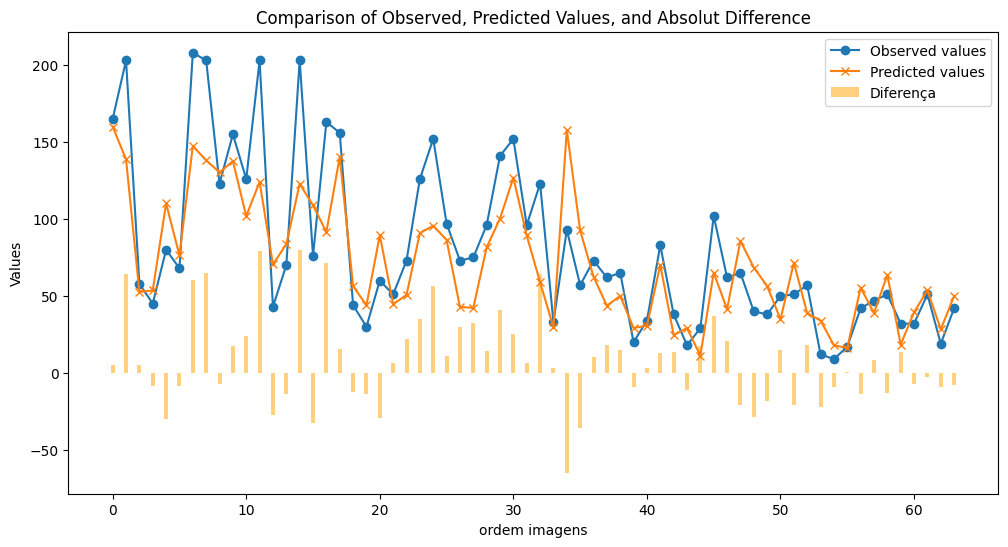

In [31]:
plt.figure(figsize=(12, 6))

# Plotando os valores observados e preditos
plt.plot(df_maior_erro.index, df_maior_erro['Observed values'], label='Observed values', marker='o')
plt.plot(df_maior_erro.index, df_maior_erro['Predicted values'], label='Predicted values', marker='x')

# Adiciona a linha da diferença
plt.bar(df_maior_erro.index, df_maior_erro['Diferença'], width=0.3, alpha=0.5, label='Diferença', color='orange')

# Adiciona rótulos e título
plt.xlabel('ordem imagens')
plt.ylabel('Values')
plt.title('Comparison of Observed, Predicted Values, and Absolut Difference')
plt.legend()

# Mostra o gráfico
plt.show()

**Interpretação**:
* No gráfico, você pode ver que as linhas de "Observed Values" e "Predicted Values" estão bastante próximas na maioria dos pontos, o que indica que o modelo está realizando previsões com boa precisão.
* No entanto, existem algumas discrepâncias visíveis, evidenciadas pelas barras de "Difference". As barras amarelas variam em magnitude e sinal, mostrando onde e em que medida o modelo errou.
* Quando as barras estão próximas de zero, o modelo fez previsões muito próximas dos valores reais. Já nas áreas onde as barras são mais altas ou baixas, as previsões do modelo se distanciaram dos valores observados.

**Conclusão**:
Esse gráfico permite avaliar visualmente o desempenho do modelo de regressão. A proximidade das linhas de valores observados e preditos sugere que o modelo está funcionando bem, mas as barras de diferença ajudam a identificar onde ele comete erros e quão grandes são esses erros.

#Previsão Frequência Relativa (%)

In [32]:
df_maior_erro['Relative Difference (%)'] = ((df_maior_erro['Predicted values']*100) / df_maior_erro['Observed values'])
df_maior_erro.head()

,Observed values,Predicted values,Lista preditos,Diferença,Relative Difference (%)
0,165,159.97,159.973953,5.03,96.951515
1,203,138.79,138.785431,64.21,68.369458
2,58,52.58,52.578583,5.42,90.655172
3,45,53.60,53.602417,-8.60,119.111111
4,80,110.10,110.103058,-30.10,137.625000


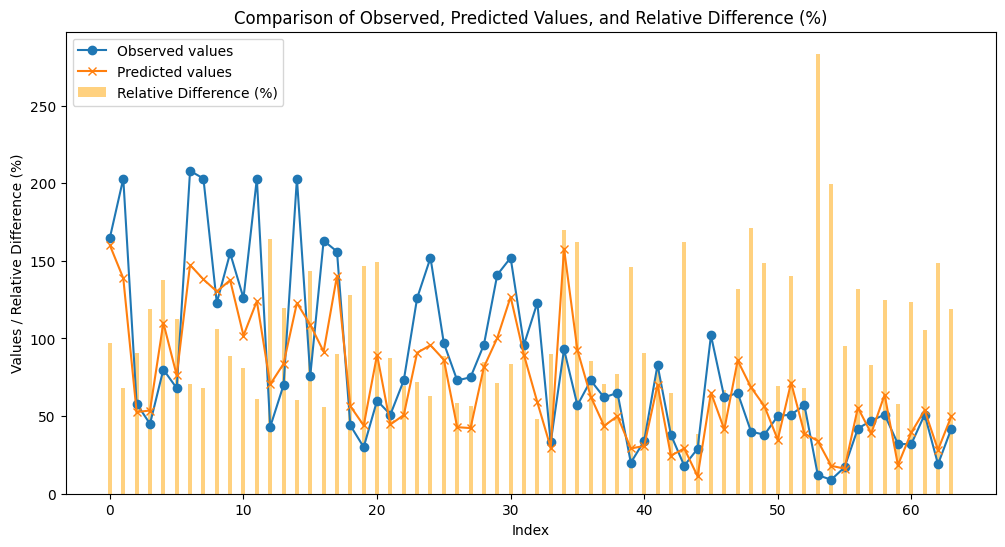

In [33]:
# Cria o gráfico comparando os valores
plt.figure(figsize=(12, 6))

# Plotando os valores observados e preditos
plt.plot(df_maior_erro.index, df_maior_erro['Observed values'], label='Observed values', marker='o')
plt.plot(df_maior_erro.index, df_maior_erro['Predicted values'], label='Predicted values', marker='x')

# Adiciona a linha da diferença relativa
plt.bar(df_maior_erro.index, df_maior_erro['Relative Difference (%)'], width=0.3, alpha=0.5, label='Relative Difference (%)', color='orange')

# Adiciona rótulos e título
plt.xlabel('Index')
plt.ylabel('Values / Relative Difference (%)')
plt.title('Comparison of Observed, Predicted Values, and Relative Difference (%)')
plt.legend()

# Mostra o gráfico
plt.show()

**Explicação**:
1. Diferença Relativa: A diferença relativa é calculada dividindo a diferença absoluta pelo valor observado e multiplicando por 100 para expressá-la como uma porcentagem.
2. Gráfico de Barras para Diferença Relativa: As barras agora representam a diferença em termos percentuais (%), mostrando onde o modelo previu valores maiores ou menores em relação aos valores reais.
3. Outros Detalhes: As linhas dos valores observados e preditos permanecem as mesmas para facilitar a comparação, mas o foco aqui está nas barras de diferença relativa.

**Interpretação**:
* Esse gráfico ajudará a visualizar melhor os erros em termos proporcionais, o que é útil especialmente quando os valores observados variam bastante. A análise de erro em termos percentuais permite ver onde o modelo está errando mais, independentemente da magnitude dos valores absolutos.

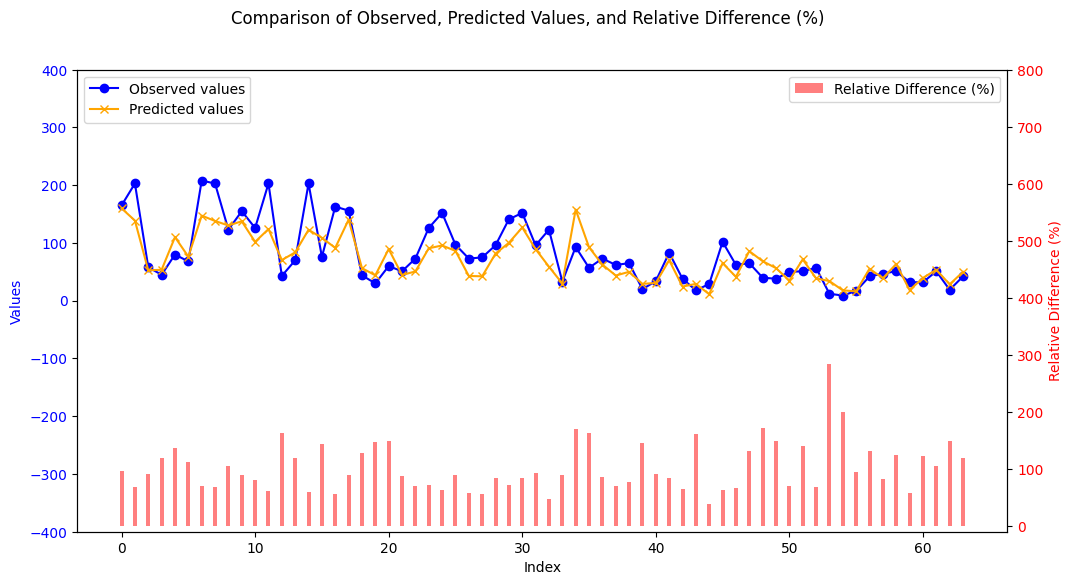

In [34]:
# Cria o gráfico com dois eixos Y
fig, ax1 = plt.subplots(figsize=(12, 6))

# Eixo Y da esquerda (para valores observados e preditos)
ax1.set_xlabel('Index')
ax1.set_ylabel('Values', color='blue')
ax1.plot(df_maior_erro.index, df_maior_erro['Observed values'], label='Observed values', marker='o', color='blue')
ax1.plot(df_maior_erro.index, df_maior_erro['Predicted values'], label='Predicted values', marker='x', color='orange')
ax1.tick_params(axis='y', labelcolor='blue')

# Mantém a escala normal do eixo Y da esquerda
# ax1.set_ylim(df_maior_erro[['Observed values', 'Predicted values']].min().min(),
#              df_maior_erro[['Observed values', 'Predicted values']].max().max())
ax1.set_ylim(-400, 400)

# Adiciona o segundo eixo Y à direita (para diferença relativa)
ax2 = ax1.twinx()
ax2.set_ylabel('Relative Difference (%)', color='red')


# Ajusta a largura das barras
bar_width = 0.3
ax2.bar(df_maior_erro.index, df_maior_erro['Relative Difference (%)'], width=bar_width, alpha=0.5, label='Relative Difference (%)', color='red')
ax2.tick_params(axis='y', labelcolor='red')

# Corrige a amplitude do eixo Y da direita para -15 a 300
ax2.set_ylim(-10, 800)

# Títulos e legendas
fig.suptitle('Comparison of Observed, Predicted Values, and Relative Difference (%)')
ax1.legend(loc='upper left')
ax2.legend(loc='upper right')

# Mostra o gráfico
plt.show()